# データサイエンス実践A 第７講：値を数える・辞書・棒グラフの補足・箱ひげ図
### 新潟大学 創生学部（2026年度）
**講義日：2026年10月27日（火）**

1. はじめに、前回の `value_counts` を復習し、**辞書**の基礎を学ぶ（Q）。
1. 次に、前回の棒グラフの補足として、**横軸の名前・項目の順番・棒の上の値・積み上げ**を学ぶ（R）。
1. そのあと、**箱ひげ図**（S-0）の**完成形と部品表**で、要点をまとめて紹介する。
1. この notebook を授業HPに公開する。CES-Alpha の演習「**第７講**」（辞書3問・棒グラフ4問・箱ひげ図3問。箱ひげ図の最後の1問は発展）を解く。
1. 解き方が分からないときは、各問題の「学ぶところ」の節（Q-1〜Q-3、R-1〜R-4、S-1〜S-7）を読む。それでも分からなければ、手を挙げて**個別に質問**する。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[Q. 値を数える・辞書](#Q.-値を数える・辞書)**（演習「第７講」の dict）
- [Q-1 Excel の列の値を数える（復習）](#Q-1-Excel-の列の値を数える（復習）)
- [Q-2 辞書の基礎](#Q-2-辞書の基礎)
- [Q-3 オプションの辞書](#Q-3-オプションの辞書)

**[R. 前回の補足：棒グラフ](#R.-前回の補足：棒グラフ)**（演習「第７講」の bar）
- [R-1 横軸の名前を書き換える](#R-1-横軸の名前を書き換える)
- [R-2 項目の順番を決める](#R-2-項目の順番を決める)
- [R-3 棒の上に値を書く](#R-3-棒の上に値を書く)
- [R-4 積み上げ棒グラフ](#R-4-積み上げ棒グラフ)

**[S. 箱ひげ図](#S.-箱ひげ図)**（演習「第７講」の box）
- [S-0 今日の完成形](#S-0-今日の完成形)
- [S-1 箱ひげ図の読み方](#S-1-箱ひげ図の読み方)
- [S-2 箱ひげ図の基本](#S-2-箱ひげ図の基本)
- [S-3 項目の名前](#S-3-項目の名前)
- [S-4 箱の幅と塗りつぶし](#S-4-箱の幅と塗りつぶし)
- [S-5 平均を表示する](#S-5-平均を表示する)
- [S-6 補助線を引く](#S-6-補助線を引く)
- [S-7 Excel のデータで箱ひげ図](#S-7-Excel-のデータで箱ひげ図)

**[T. 発展（できる人だけ）](#T.-発展（できる人だけ）)**
- [T-1 箱ごとに色を変える](#T-1-箱ごとに色を変える)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は **Excel ファイルを読み**（`pd.read_excel`）、**棒グラフ**（`plt.bar`）と**円グラフ**（`plt.pie`）を描いた
- 新しい notebook はいつもの場所（ホームフォルダ）に作る。`dsa2026data.xlsx` も同じ場所に置いておく。今日も使う
- 列の取り出しは `df['列名']`、列名の一覧は `list(df.columns)`
- 説明文は**マークダウン**で書く（第３講 F-4）。課題の notebook でも、グラフの説明や考察はマークダウンのセルに書く
- 第１回課題の提出、おつかれさまでした
- 補助線の向き：`plt.axhline` の **h** は horizontal（**横**の線、`y=` で高さを指定）、`plt.axvline` の **v** は vertical（**縦**の線、`x=` で位置を指定）
- 色の組み合わせ：何も指定しないときは **tab10**（1本目は青、2本目はオレンジ、3本目は緑…）。替え方は、下の準備のセルを実行したあとで試す

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')
df.head()

,name,国語,数学,理科,社会,英語
0,伊藤 涼介,94,76,62,81,62
1,上田 美咲,63,57,59,80,74
2,木村 太郎,55,66,82,78,66
3,佐藤 亜美,61,87,80,65,78
4,鈴木 恵美子,56,58,69,97,61


- 表が出れば準備完了。`FileNotFoundError` が出たら、`dsa2026data.xlsx` を notebook と同じ場所に置く（第５講 L-1）
- `exam` シートは、30人の5教科のテストの点数（名前は架空）

### 色の組み合わせを替える（前回のコメントから）

- `plt.pie` の括弧の中に `colors=` を書き足すと、そのグラフの色の組み合わせが替わる。そのグラフだけに効くので、次のグラフには影響しない
- `'Set2'` の部分は `'Pastel1'`、`'Dark2'` などに替えられる（第６講 P-2、[色の組み合わせの一覧](https://matplotlib.org/stable/users/explain/colors/colormaps.html#qualitative)）
- 一覧の **Qualitative**（色どうしがはっきり違う組み合わせ）の中から選ぶ。第５講の散布図で `cmap=` に使った `'viridis'`・`'coolwarm'` などは、値の大きさに合わせて色が少しずつ変わる組み合わせで、散布図のように連続的に変わる値を色で表すときに使う。円グラフや棒グラフのように項目の違いをはっきり見せたいときは Qualitative、と使い分ける
- 名前の末尾に `_r` を付けると、色の順番が逆になる（例：`'Set2_r'`）

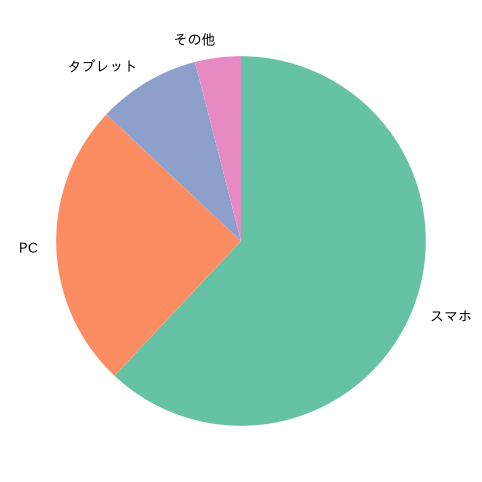

In [2]:
plt.figure(figsize=(6, 6))
plt.pie([62, 25, 9, 4], labels=['スマホ', 'PC', 'タブレット', 'その他'], startangle=90, counterclock=False,
        colors=plt.get_cmap('Set2').colors)  # 色の組み合わせを Set2 に
plt.show()

- 棒グラフでは引数名が `color=`（s なし）になる。`plt.bar(x, y, color=plt.get_cmap('Set2').colors)` と書くと、棒が1本ずつ違う色になる
- このあとのグラフをまとめて替えたいときは、グラフを描く前に次の1行を実行する。それ以降のグラフ（棒・円・折れ線）がすべてその色の組み合わせになる。折れ線を何本も描くグラフの色を揃えたいときに便利

```python
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.get_cmap('Set2').colors)  # 以降のグラフを Set2 に
```

- 元に戻すときは `'Set2'` を `'tab10'` にして実行する（`'tab10'` が最初から使われている色の組み合わせ）

---
# Q. 値を数える・辞書

前回の O-7 では、`value_counts()` で曜日ごとの件数を数えた。「何をしているのか分かりにくかった」という声が多かったので、もう一度確かめてから、辞書の基礎を学ぶ。

## Q-1 Excel の列の値を数える（復習）

- `df['列名'].value_counts()` で、その列に**同じ値が何件あるか**を数える
- `tip_data` シートは、あるレストランの244件の会計の記録（食事代・チップ・性別・曜日など）
- ここでは `smoker` 列（グループに喫煙者がいたか：Yes / No）の件数を数える

In [3]:
df_tip = pd.read_excel('dsa2026data.xlsx', sheet_name='tip_data')
count = df_tip['smoker'].value_counts()
count

smoker
No     151
Yes     93
Name: count, dtype: int64

- 左の列（No, Yes）が **index**（数えた値の名前）、右の列が**件数**。件数の多い順に並ぶ
- `count.index` で名前だけ、`count.values` で件数だけを取り出せる

In [4]:
print(count.index)
print(count.values)

Index(['No', 'Yes'], dtype='str', name='smoker')
[151  93]


- 名前を横軸、件数を棒の高さにすれば棒グラフになる（`plt.bar(count.index, count)` と書いても同じ）

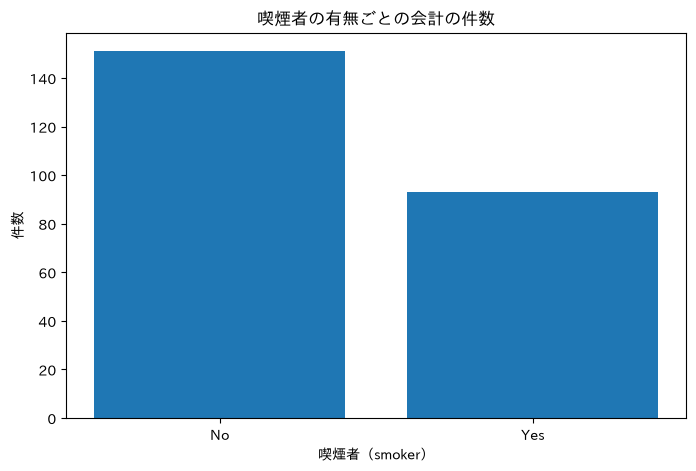

In [5]:
plt.figure(figsize=(8, 5))
plt.bar(count.index, count.values)
plt.title('喫煙者の有無ごとの会計の件数')
plt.xlabel('喫煙者（smoker）')
plt.ylabel('件数')
plt.show()

## Q-2 辞書の基礎

- **辞書**は、「**キー**（名前）」と「**値**」を `:` でつないだ組を、`{ }` の中に並べたもの
- リストは番号（`[0]`, `[1]`, …）で取り出すが、辞書は**キー**で取り出す
- 例：在籍番号（キー）と名前（値）の組（架空のデータ）

In [6]:
students = {'S001': '新潟 太郎', 'S002': '古町 花子', 'S003': '万代 次郎'}

print(students['S002'])
print(len(students))

古町 花子
3


- `辞書['キー']` で、そのキーの値を取り出す
- `len(辞書)` で、組の個数が分かる
- `辞書['キー'] = 値` で、組を**追加**する。すでにあるキーなら、値が**上書き**される

In [7]:
students['S004'] = '白山 さくら'
students['S001'] = '新潟 一郎'

print(students)

{'S001': '新潟 一郎', 'S002': '古町 花子', 'S003': '万代 次郎', 'S004': '白山 さくら'}


- 同じキーは2つ持てない。`'S001'` は追加ではなく上書きになった
- ないキーを指定すると `KeyError: 'S005'` というエラーになる（エラー文の最後に、見つからなかったキーが出る）
- Q-1 の `value_counts()` の結果も「名前と件数の組」なので、辞書と同じように `count['No']` で取り出せる（今の `count` は `smoker` 列を数えたもの）

▶ **演習**：`dict_第７講1`（在籍番号と名前の辞書）、`dict_第７講2`（値を直して表示する）

## Q-3 オプションの辞書

- 前回の円グラフの `wedgeprops={'edgecolor': 'w'}` は、「扇の部品（wedge）の設定（props）」を辞書で渡していた。キーが**設定の名前**、値が**設定値**
- 設定が2つ以上あるときは、`,` で区切って並べる

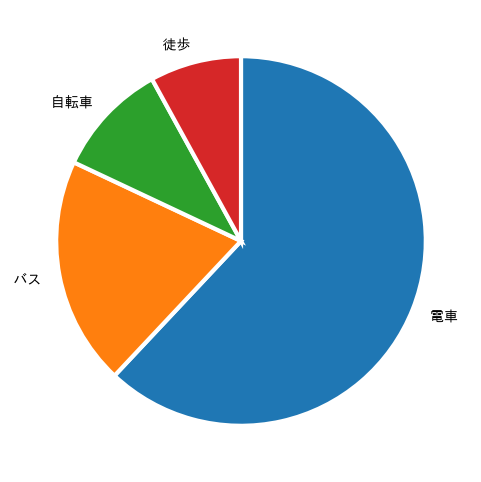

In [8]:
plt.figure(figsize=(6, 6))
plt.pie([62, 20, 10, 8], labels=['電車', 'バス', '自転車', '徒歩'], startangle=90, counterclock=False,
        wedgeprops={'edgecolor': 'w', 'linewidth': 3})
plt.show()

- `'linewidth': 3` で境目の線を太くした
- このあとの箱ひげ図（S-4）の `boxprops={'facecolor': 'lightblue'}` も同じ形（箱の部品の設定）

▶ **演習**：`dict_第７講3`（円グラフの境目を辞書で指定する）

---
# R. 前回の補足：棒グラフ

棒グラフを描くときによく使う操作を4つ補足する。データは Q-1 で読み込んだ `df_tip`（tip_data シート）。R-1 で曜日ごとの件数 `count` を数え直す。

## R-1 横軸の名前を書き換える

- `plt.xticks(元の名前, 新しい名前)` で、横軸の名前を書き換える。2つのリストは**同じ順番・同じ個数**にする
- 文字が重なるときは `rotation=45`（45度傾ける）

Index(['Sat', 'Sun', 'Thur', 'Fri'], dtype='str', name='day')


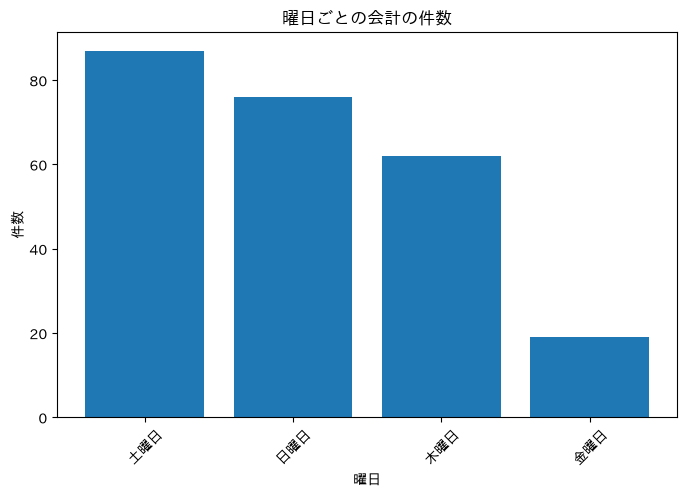

In [9]:
count = df_tip['day'].value_counts()
print(count.index)

plt.figure(figsize=(8, 5))
plt.bar(count.index, count.values)
plt.xticks(count.index, ['土曜日', '日曜日', '木曜日', '金曜日'], rotation=45)
plt.title('曜日ごとの会計の件数')
plt.xlabel('曜日')
plt.ylabel('件数')
plt.show()

- `count.index` は Sat, Sun, Thur, Fri の順（件数の多い順）。だから新しい名前も「土曜日, 日曜日, 木曜日, 金曜日」の順に書く
- `rotation=45` で、名前を45度傾けた。長い名前が隣と重なるときに使う
- 箱ひげ図の項目の名前（S-3）も同じ `plt.xticks` で付ける

▶ **演習**：`bar_第７講1`（曜日の名前を日本語にする）

## R-2 項目の順番を決める

- `value_counts()` は件数の**多い順**に並べる。曜日のように**決まった順番**で並べたいときは、後ろに `.reindex([順番のリスト])` を付ける
- ここでは曜日の順（木・金・土・日）に並べる

In [10]:
count = df_tip['day'].value_counts().reindex(['Thur', 'Fri', 'Sat', 'Sun'])
count

day
Thur    62
Fri     19
Sat     87
Sun     76
Name: count, dtype: int64

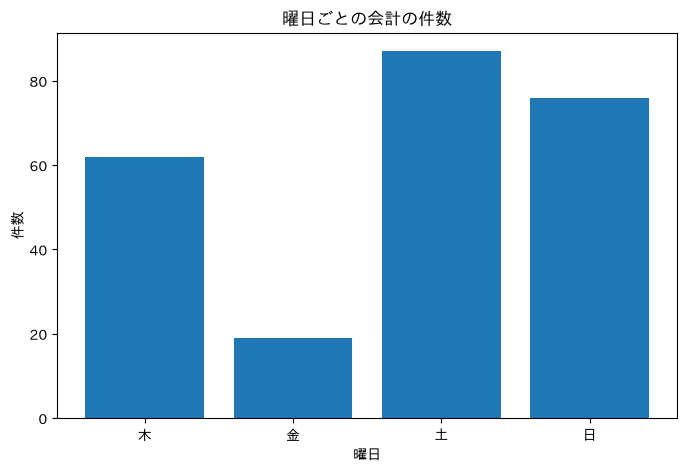

In [11]:
plt.figure(figsize=(8, 5))
plt.bar(count.index, count.values)
plt.xticks(count.index, ['木', '金', '土', '日'])
plt.title('曜日ごとの会計の件数')
plt.xlabel('曜日')
plt.ylabel('件数')
plt.show()

- `reindex` のリストには、`count.index` にある名前を**つづりも同じに**書く（`'Thu'` と書くと、その棒は件数なし（NaN）になる）
- ほかの並べ方：件数の少ない順は `.sort_values()`、名前の順（アルファベット順・数の順）は `.sort_index()`
- 人数（`size`）のように**数**の項目は、横軸の位置が数で決まるので、並べ替えなくても 1, 2, 3, … の順に並ぶ

▶ **演習**：`bar_第７講2`（曜日の順に並べる）

## R-3 棒の上に値を書く

- `plt.bar(...)` の結果を変数（ここでは `b`）に入れ、`plt.bar_label(b)` と書くと、棒の上に高さの値が書かれる

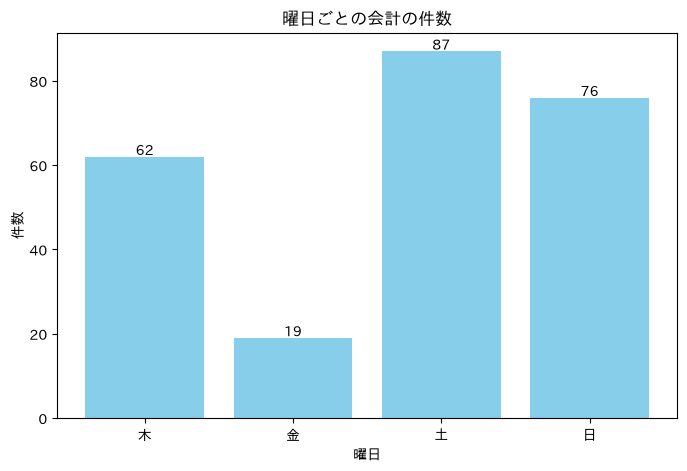

In [12]:
plt.figure(figsize=(8, 5))
b = plt.bar(count.index, count.values, color='skyblue')
plt.bar_label(b)
plt.xticks(count.index, ['木', '金', '土', '日'])
plt.title('曜日ごとの会計の件数')
plt.xlabel('曜日')
plt.ylabel('件数')
plt.show()

- 小数の桁をそろえるときは `plt.bar_label(b, fmt='%.1f')`（小数第1位まで）。`'%.1f'` は円グラフの `autopct='%.1f%%'`（第６講）と同じ書き方
- 棒の**中**に書くときは `label_type='center'`（R-4 で使う）

▶ **演習**：`bar_第７講3`（棒の上に件数を書く）

## R-4 積み上げ棒グラフ

- 曜日ごとの件数を、男性と女性に分けて**積み上げる**
- 2回目の `plt.bar` に `bottom=1回目の高さ` を付けると、その上に積まれる。`label=` と `plt.legend()` で凡例を付ける
- 男女別の件数は、ここでは数えた結果を手で書く（データから男女別に数える方法は後の講義で）

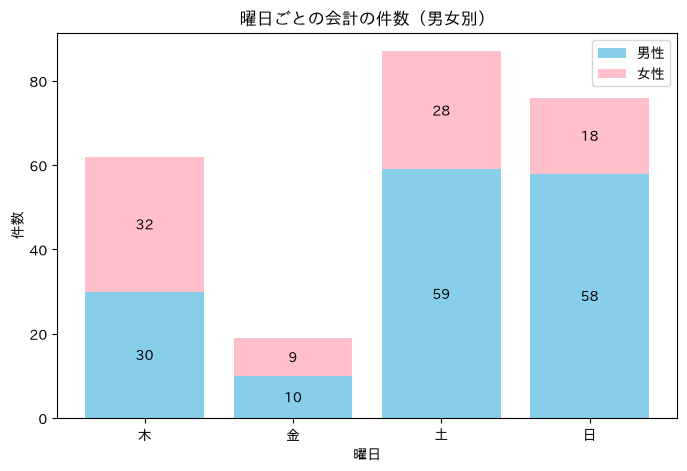

In [13]:
day = ['Thur', 'Fri', 'Sat', 'Sun']
male = [30, 10, 59, 58]
female = [32, 9, 28, 18]

plt.figure(figsize=(8, 5))
b1 = plt.bar(day, male, color='skyblue', label='男性')
b2 = plt.bar(day, female, bottom=male, color='pink', label='女性')
plt.bar_label(b1, label_type='center')
plt.bar_label(b2, label_type='center')
plt.xticks(day, ['木', '金', '土', '日'])
plt.title('曜日ごとの会計の件数（男女別）')
plt.xlabel('曜日')
plt.ylabel('件数')
plt.legend()
plt.show()

- `bottom=male` を消すと、女性の棒が男性の棒に**重なって**描かれる（積み上がらない）
- 男女を足した高さは、R-2 の曜日ごとの件数と同じになる（木：30 + 32 = 62）

▶ **演習**：`bar_第７講4`（喫煙・禁煙の積み上げ棒グラフ）

---
# S. 箱ひげ図

**箱ひげ図**は、いくつかのグループの**ばらつき**を並べて比べるグラフ。点数が**どのあたりに集まっているか**を、5つの数にまとめて表す。

演習「第７講」の箱ひげ図の問題（box）のひな形は S-2 にある。

## S-0 今日の完成形

今日はこのグラフを目指す（30人の5教科の点数のばらつき）。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する（`Shift + Enter`）
1. まずは**数値や文字を変えて**、グラフのどこが変わるかを確かめる
1. そのあと、箱ひげ図の読み方（S-1）を確かめてから、各部品（[0]〜[7]）の働きを学ぶ（S-2〜S-7）

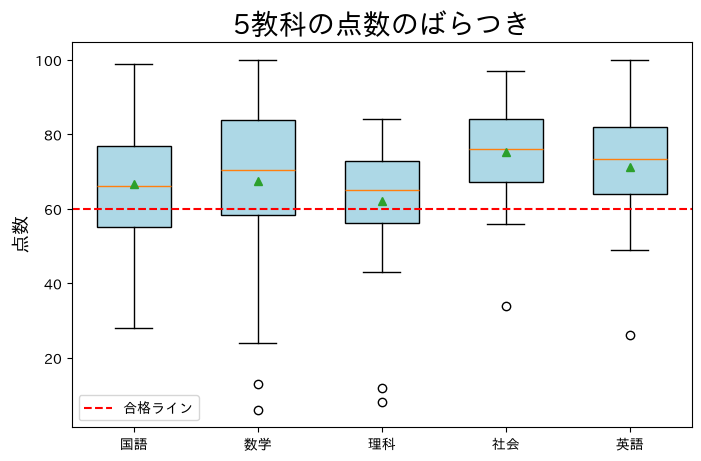

In [14]:
df = pd.read_excel('dsa2026data.xlsx', sheet_name='exam')  # Excel を読む

plt.figure(figsize=(8, 5))  # [0] グラフの大きさ
plt.boxplot([df['国語'], df['数学'], df['理科'], df['社会'], df['英語']],  # [1] 箱ひげ図 [6] Excel の列を並べる
            widths=0.6, patch_artist=True, boxprops={'facecolor': 'lightblue'},  # [3] 箱の幅と塗りつぶし
            showmeans=True)  # [4] 平均
plt.xticks([1, 2, 3, 4, 5], ['国語', '数学', '理科', '社会', '英語'])  # [2] 項目の名前
plt.axhline(y=60, color='r', linestyle='--', label='合格ライン')  # [5] 補助線
plt.title('5教科の点数のばらつき', fontsize=20)  # [7] タイトル
plt.ylabel('点数', fontsize=14)  # [7] 縦軸の名前
plt.legend()  # [7] 凡例
plt.show()

- `plt.boxplot(...)` は1つの命令。長いので `,` の後ろで**改行**している（`(` の中なら、次の行も続きとして読まれる。第６講 O-0）

### 変えてみよう（1か所変えたら、もう一度実行する）

- 色：`'lightblue'` → `'pink'`、`'lightgreen'`
- 幅：`widths=0.6` → `widths=0.3`、`widths=1`
- `showmeans=True` を `showmeans=False` にすると、何が消えるか
- 合格ライン：`y=60` → `y=70`
- `plt.xticks(...)` の行頭に `#` を付けると、横軸の下がどうなるか

In [15]:
# 上のコードを貼り付けて、値を変えてみよう

| 番号 | 部品 | 書き方 | 学ぶところ | 演習「第７講」 |
|---|---|---|---|---|
| [0] | グラフの大きさ（基本設定） | `plt.figure(figsize=(8, 5))` | 第３講 | （どの問題でも書いてよい） |
| [1] | 箱ひげ図を描く | `plt.boxplot([データ1, データ2, …])` | S-2 | （ひな形） |
| [2] | 項目の名前 | `plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` | S-3 | `box_第７講1`、`box_第７講2` |
| [3] | 箱の幅と塗りつぶし | `widths=0.6`、`patch_artist=True, boxprops={'facecolor': '色'}` | S-4 | `box_第７講1` |
| [4] | 平均を表示する | `showmeans=True` | S-5 | `box_第７講2` |
| [5] | 補助線 | `plt.axhline(y=60, label='合格ライン')` | S-6 | `box_第７講2` |
| [6] | Excel の列を並べる | `[df['国語'], df['数学'], …]` | S-7 | （演習なし） |
| [7] | タイトル・軸の名前・凡例 | `plt.title`、`plt.legend()` など | 第３講 | （書いてもよい。`box_第７講2` では凡例が必要） |
| | 箱ごとに色を変える | `bp['boxes']` と for 文 | T-1（発展） | `box_描画基礎005` |

- 演習では、**問題で指定されたものだけ**書く（完成形をそのまま貼らない）

## S-1 箱ひげ図の読み方

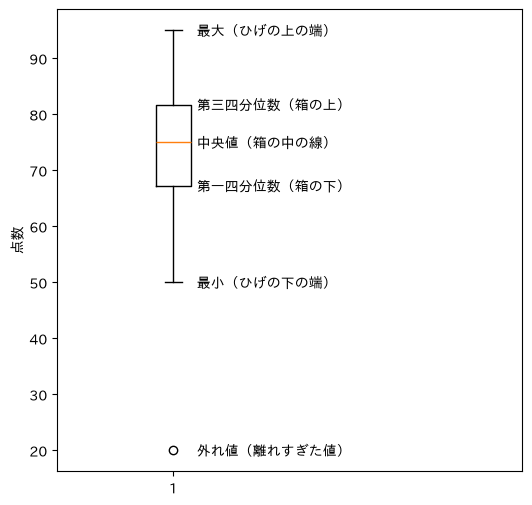

In [16]:
data = [50, 52, 58, 61, 63, 65, 67, 68, 70, 71, 72, 73, 74, 75, 75,
        76, 77, 78, 79, 80, 81, 82, 84, 85, 86, 88, 90, 92, 95, 20]

plt.figure(figsize=(6, 6))
plt.boxplot(data)
plt.text(1.1, np.max(data[:-1]), '最大（ひげの上の端）', va='center')
plt.text(1.1, np.percentile(data, 75), '第三四分位数（箱の上）', va='center')
plt.text(1.1, np.median(data), '中央値（箱の中の線）', va='center')
plt.text(1.1, np.percentile(data, 25), '第一四分位数（箱の下）', va='center')
plt.text(1.1, np.min(data[:-1]), '最小（ひげの下の端）', va='center')
plt.text(1.1, 20, '外れ値（離れすぎた値）', va='center')
plt.xlim(0.5, 2.5)
plt.ylabel('点数')
plt.show()

| 部分 | 意味 |
|---|---|
| 箱の中の線 | **中央値**（大きさの順に並べて真ん中の値） |
| 箱 | 第一四分位数から第三四分位数まで（四分位範囲、第４講 G-2）。真ん中の半分（50%）の人が入る範囲。箱が**長いほどばらつきが大きい** |
| ひげ | 外れ値を除いた最小から最大まで |
| ○ | **外れ値**（ほかから離れすぎた値）。箱の長さの 1.5 倍より外にある値 |

- 上の図の文字は `plt.text`（第４講 H-10 で使った。くわしくは後の講義で）で書いている。今は読み方だけ分かればよい

## S-2 箱ひげ図の基本

- `plt.boxplot([データ1, データ2, …])` で、グループごとの箱が**左から順に**並ぶ
- データは**リストのリスト**（`[ ]` の中にリストを並べる）で渡す
- 演習「第７講」の箱ひげ図の問題（box）のひな形は次の形

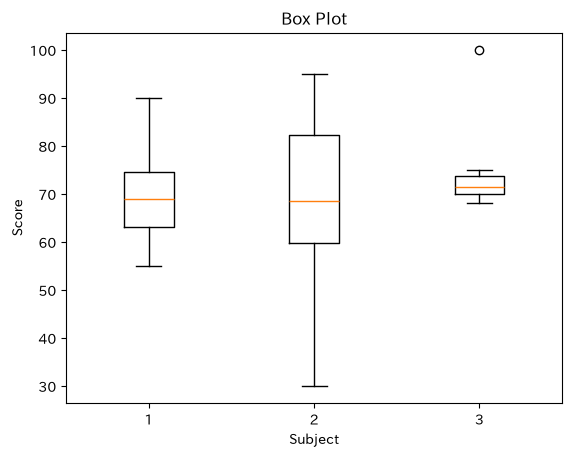

In [17]:
japanese = [62, 75, 58, 81, 70, 66, 90, 55, 73, 68]
math = [45, 88, 62, 95, 30, 71, 84, 59, 77, 66]
english = [70, 72, 68, 75, 74, 69, 71, 73, 100, 70]

plt.boxplot([japanese, math, english])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- 数学（2番目）は箱が長い＝点数がばらばら。英語（3番目）は箱が短い＝みんな同じくらい。英語の 100 点は外れ値（○）
- 箱が1つだけなら `plt.boxplot(japanese)` でもよい

## S-3 項目の名前

- 横軸の下には `1, 2, 3` と番号が付く。`plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` で名前に置き換える
- 番号と名前は**同じ個数**にする

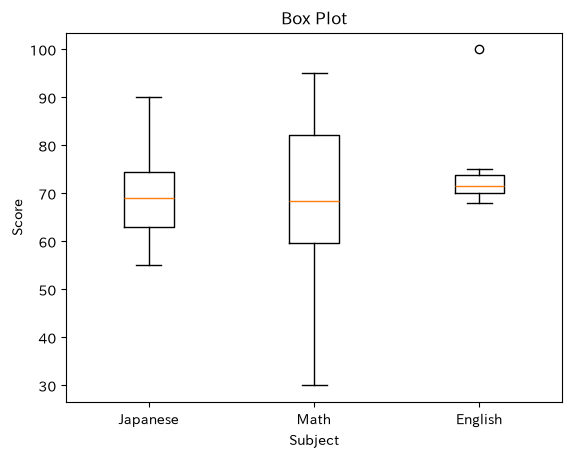

In [18]:
plt.boxplot([japanese, math, english])
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- `plt.boxplot(..., tick_labels=['Japanese', 'Math', 'English'])` と書いても同じ（matplotlib 3.9 より古いと `labels=`）。どの環境でも動くので、この授業では `plt.xticks` を使う

## S-4 箱の幅と塗りつぶし

- `widths=0.6` で箱の幅を変える（何も書かないと、箱の数に合わせて 0.15〜0.5 の間で決まる。`1` で隣の箱とくっつく）
- `patch_artist=True` で箱の中を**塗りつぶす**（何も書かないと白抜き）。塗る色は `boxprops={'facecolor': '色'}`

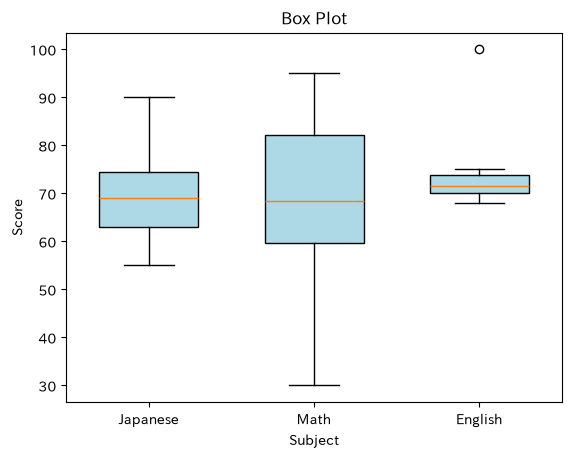

In [19]:
plt.boxplot([japanese, math, english], widths=0.6, patch_artist=True, boxprops={'facecolor': 'lightblue'})
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

- `boxprops={'facecolor': 'lightblue'}` は Q-3 のオプションの辞書。「箱の部品の、中の色は lightblue」と読む

▶ **演習**：`box_第７講1`（項目の名前と、箱の幅・塗りつぶし）

## S-5 平均を表示する

- 箱の中の線は**中央値**で、平均ではない。`showmeans=True` で**平均**を ▲ で表示する
- 外れ値があると、平均は中央値から外れ値の側へずれる

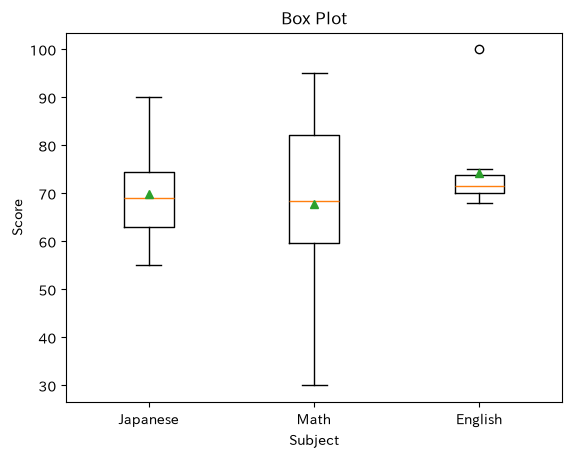

In [20]:
plt.boxplot([japanese, math, english], showmeans=True)
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

## S-6 補助線を引く

- 第４講の `plt.axhline(y=値)` が箱ひげ図でも使える。合格ラインや全体の平均を引く

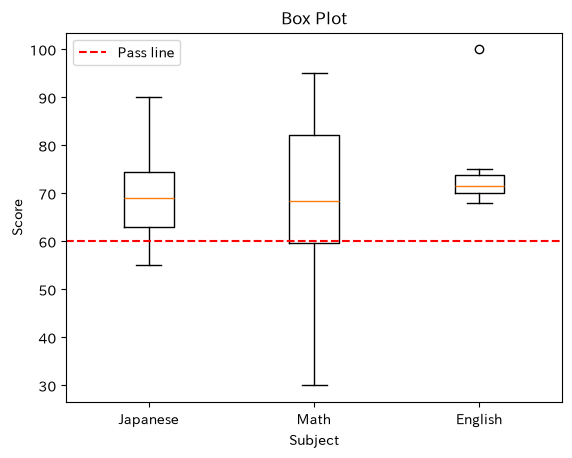

In [21]:
plt.boxplot([japanese, math, english])
plt.axhline(y=60, color='r', linestyle='--', label='Pass line')
plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.legend()
plt.show()

▶ **演習**：`box_第７講2`（平均の表示と、合格ラインの補助線）

## S-7 Excel のデータで箱ひげ図

- `exam` シートの5教科を並べる。`df['国語']` などを**リストの中に**並べて渡す

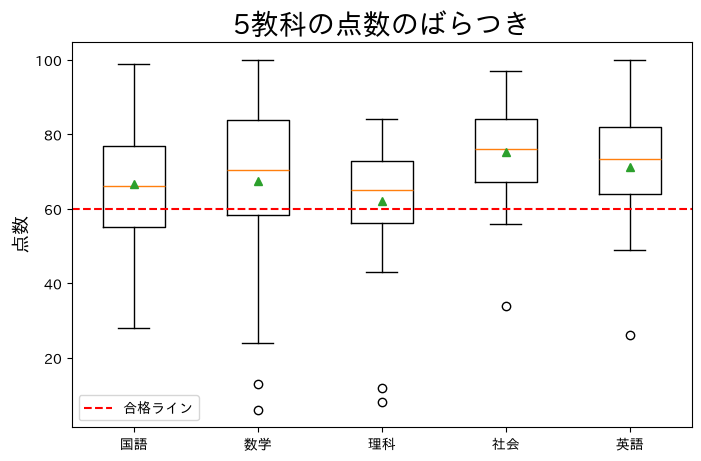

In [22]:
plt.figure(figsize=(8, 5))
plt.boxplot([df['国語'], df['数学'], df['理科'], df['社会'], df['英語']], showmeans=True)
plt.xticks([1, 2, 3, 4, 5], ['国語', '数学', '理科', '社会', '英語'])
plt.axhline(y=60, color='r', linestyle='--', label='合格ライン')
plt.title('5教科の点数のばらつき', fontsize=20)
plt.ylabel('点数', fontsize=14)
plt.legend()
plt.show()

### 使ってみよう
- 社会は箱が短く、数学は長い。点数のばらつきが大きいのはどの教科か
- 理科の下にある ○ は誰の点数か、`df` の表で探してみよう

In [23]:
# ここで試してみよう

---
# T. 発展（できる人だけ）

ここは授業の本編ではない。課題に使わなくても困らない。

## T-1 箱ごとに色を変える

- `patch_artist=True` を付けて描いた結果を変数（ここでは `bp`）に入れると、`bp['boxes']` で箱を1つずつ取り出せる。`bp` は Q-2 の辞書で、`'boxes'` がキー
- 後の講義で学ぶ for 文で、箱ごとに色を塗る

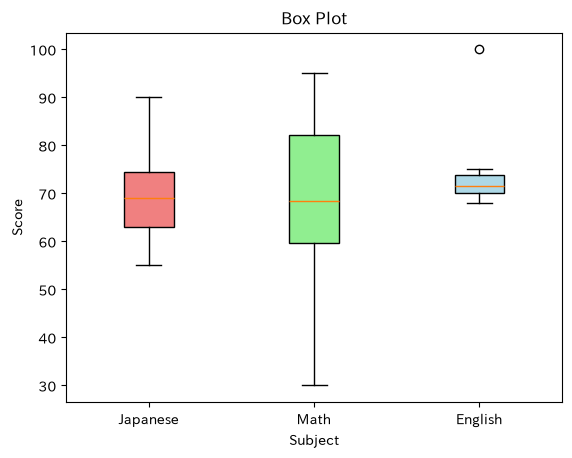

In [24]:
bp = plt.boxplot([japanese, math, english], patch_artist=True)
mycolor = ['lightcoral', 'lightgreen', 'lightblue']
for box, c in zip(bp['boxes'], mycolor):
    box.set_facecolor(c)

plt.xticks([1, 2, 3], ['Japanese', 'Math', 'English'])
plt.title('Box Plot')
plt.xlabel('Subject')
plt.ylabel('Score')
plt.show()

▶ **演習**（発展）：`box_描画基礎005`

---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| **以下は値を数える・辞書** | |
| 値を数える | `count = df['列名'].value_counts()` |
| 名前・件数を取り出す | `count.index`（名前）、`count.values`（件数） |
| 辞書を作る | `d = {'キー1': 値1, 'キー2': 値2}` |
| 取り出す・追加する | `d['キー']`、`d['キー'] = 値`（あるキーなら上書き） |
| オプションの辞書 | `wedgeprops={'edgecolor': 'w', 'linewidth': 3}` |
| **以下は棒グラフの補足** | |
| 横軸の名前を書き換える | `plt.xticks(count.index, ['新しい名前', …])`、傾けるなら `rotation=45` |
| 項目の順番 | `.reindex(['Thur', 'Fri', 'Sat', 'Sun'])`、`.sort_values()`、`.sort_index()` |
| 棒の上に値 | `b = plt.bar(...)` → `plt.bar_label(b)`（`fmt='%.1f'`、`label_type='center'`） |
| 積み上げ | 2回目の `plt.bar` に `bottom=1回目の高さ` |
| **以下は箱ひげ図** | |
| 箱ひげ図 | `plt.boxplot([データ1, データ2, …])` |
| 項目の名前 | `plt.xticks([1, 2, 3], ['名前1', '名前2', '名前3'])` |
| 箱の幅・塗りつぶし | `widths=0.6`、`patch_artist=True, boxprops={'facecolor': '色'}` |
| 平均を表示 | `showmeans=True` |
| 補助線 | `plt.axhline(y=60)` |